# AAI 540 SageMaker benchmark, model development, evaluation, and deployment

This notebook is the modeling continuation of `AAI540_SageMaker_DataLake_FeatureStore.ipynb` for the **Retrieval-Augmented Product Question Answering** project. It:

1. discovers a completed, versioned data run in Amazon S3;
2. trains a deliberately small **two-feature benchmark** in a SageMaker training job;
3. trains and debugs a class-balanced **random-forest candidate** in a second SageMaker training job;
4. compares both frozen artifacts on the untouched product-grouped test split using macro F1 and per-question NDCG; and
5. deploys the candidate through **SageMaker Batch Transform** against the production split.

Batch Transform was selected instead of an always-on endpoint because the first product-QA MVP can score candidate evidence asynchronously, the job automatically releases compute, and it avoids idle endpoint cost.

**Leakage controls:** the upstream notebook groups splits by ASIN (with qid fallback); this notebook rechecks group disjointness. Features derived from the gold `answer` field are excluded from both models because that field is not guaranteed to exist at inference time.

## Prerequisites and permissions

Run this notebook in a SageMaker AI JupyterLab Space from the same project directory as `src/train.py`. First complete the data-lake notebook and retain its S3 run artifacts.

The execution role needs access to the project S3 prefix plus permissions for SageMaker training, model creation, Batch Transform, CloudWatch Logs, ECR image pulls, and `iam:PassRole`. The default instance types are intentionally small; change them only if your lab allow-list requires a different type.

The notebook pins the SageMaker Scikit-learn container to framework version `1.4-2` and installs the matching local Scikit-learn version so downloaded model artifacts can be evaluated without a serialization-version mismatch.

In [1]:
%pip install -q --upgrade \
    "boto3>=1.34" \
    "botocore>=1.34" \
    "sagemaker>=2.232,<3" \
    "pandas>=2.1,<3" \
    "pyarrow>=15,<22" \
    "scikit-learn==1.4.2" \
    "joblib>=1.3,<2" \
    "matplotlib>=3.8,<4" \
    "seaborn>=0.13,<1"

Note: you may need to restart the kernel to use updated packages.


> Restart the kernel only if the package cell reports that a loaded package could not be upgraded. Training and Batch Transform create billable AWS jobs; the configuration flags make those actions explicit and easy to disable during review.

In [4]:
import json
import os
import tarfile
from datetime import datetime, timezone
from pathlib import Path

import boto3
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from botocore.config import Config
from IPython.display import display
from sagemaker.inputs import TrainingInput
from sagemaker.sklearn.estimator import SKLearn
from sklearn.metrics import confusion_matrix

from src.train import (
    BENCHMARK_FEATURES,
    CANDIDATE_FEATURES,
    CLASS_LABELS,
    evaluate_model,
    probability_matrix,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

## 1 Configuration and AWS preflight

In [5]:
# ---------- User-editable settings ----------
PROJECT_NAME = "product-qa"
AWS_REGION_OVERRIDE = ""              # Blank uses the current AWS session Region.
S3_BUCKET_OVERRIDE = ""               # Blank uses sagemaker-<region>-<account-id>.
EXECUTION_ROLE_ARN_OVERRIDE = ""       # Set if automatic role inference is not correct.
SOURCE_RUN_ID_OVERRIDE = ""            # Blank discovers the newest run_summary.json.
RANDOM_SEED = 540

TRAIN_INSTANCE_TYPE = "ml.m5.large"
TRANSFORM_INSTANCE_TYPE = "ml.m5.large"
SKLEARN_FRAMEWORK_VERSION = "1.4-2"

RUN_TRAINING_JOBS = True
RUN_BATCH_TRANSFORM = True
REQUIRE_BENCHMARK_IMPROVEMENT = True

# Only used when RUN_TRAINING_JOBS=False.
BENCHMARK_JOB_NAME = ""
CANDIDATE_JOB_NAME = ""
# -------------------------------------------

session = boto3.Session(region_name=AWS_REGION_OVERRIDE or None)
region = session.region_name or os.getenv("AWS_REGION") or os.getenv("AWS_DEFAULT_REGION")
if not region:
    raise RuntimeError("No AWS Region is configured. Set AWS_REGION_OVERRIDE and rerun this cell.")

retry_config = Config(retries={"max_attempts": 10, "mode": "adaptive"})
s3 = session.client("s3", config=retry_config)
sm_client = session.client("sagemaker", config=retry_config)
sts = session.client("sts")
identity = sts.get_caller_identity()
account_id = identity["Account"]
caller_arn = identity["Arn"]

def infer_execution_role_arn(caller_identity_arn, account):
    if ":assumed-role/" in caller_identity_arn:
        role_part = caller_identity_arn.split(":assumed-role/", 1)[1].rsplit("/", 1)[0]
        return f"arn:aws:iam::{account}:role/{role_part}"
    if ":role/" in caller_identity_arn:
        return caller_identity_arn
    return ""

execution_role_arn = EXECUTION_ROLE_ARN_OVERRIDE or infer_execution_role_arn(caller_arn, account_id)
if not execution_role_arn:
    raise RuntimeError("Could not infer the SageMaker execution role. Set EXECUTION_ROLE_ARN_OVERRIDE.")

bucket = S3_BUCKET_OVERRIDE or f"sagemaker-{region}-{account_id}"
model_run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
model_prefix = f"aai540/{PROJECT_NAME}/modeling/{model_run_id}"
local_dir = Path("/tmp") / f"aai540_modeling_{model_run_id}"
local_dir.mkdir(parents=True, exist_ok=True)

print(json.dumps({
    "region": region,
    "caller_arn": caller_arn,
    "execution_role_arn": execution_role_arn,
    "bucket": bucket,
    "model_run_id": model_run_id,
    "model_s3_root": f"s3://{bucket}/{model_prefix}/",
}, indent=2))

{
  "region": "us-east-1",
  "caller_arn": "arn:aws:sts::070881885726:assumed-role/LabRole/SageMaker",
  "execution_role_arn": "arn:aws:iam::070881885726:role/LabRole",
  "bucket": "sagemaker-us-east-1-070881885726",
  "model_run_id": "20261017_012600",
  "model_s3_root": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/modeling/20261017_012600/"
}


## 2 Discover and validate the upstream data run

In [6]:
def split_s3_uri(uri):
    if not uri.startswith("s3://"):
        raise ValueError(f"Expected an S3 URI, got: {uri}")
    bucket_name, _, key = uri[5:].partition("/")
    return bucket_name, key

data_runs_prefix = f"aai540/{PROJECT_NAME}/runs/"
if SOURCE_RUN_ID_OVERRIDE:
    summary_key = f"{data_runs_prefix}{SOURCE_RUN_ID_OVERRIDE}/run_summary.json"
    selected_summary = {"Key": summary_key, "LastModified": None}
else:
    summaries = []
    paginator = s3.get_paginator("list_objects_v2")
    for page in paginator.paginate(Bucket=bucket, Prefix=data_runs_prefix):
        summaries.extend(
            item for item in page.get("Contents", [])
            if item["Key"].endswith("/run_summary.json")
        )
    if not summaries:
        raise FileNotFoundError(
            f"No run_summary.json found below s3://{bucket}/{data_runs_prefix}. "
            "Run the data-lake notebook first or set SOURCE_RUN_ID_OVERRIDE."
        )
    selected_summary = max(summaries, key=lambda item: item["LastModified"])
    summary_key = selected_summary["Key"]

run_summary = json.loads(s3.get_object(Bucket=bucket, Key=summary_key)["Body"].read())
required_splits = {"train", "validation", "test", "production"}
available_splits = set(run_summary.get("split_data", {}))
if available_splits != required_splits:
    raise ValueError(f"Expected split_data keys {sorted(required_splits)}, got {sorted(available_splits)}")

source_run_id = run_summary["run_id"]
print(f"Selected upstream run: {source_run_id}")
print(f"Run summary: s3://{bucket}/{summary_key}")
display(pd.Series(run_summary, name="value").to_frame())

Selected upstream run: 20261017_011905
Run summary: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20261017_011905/run_summary.json


,value
run_id,20261017_011905
schema_version,epqa-csv-title-v1
record_id_strategy,"sha256(source_split,qid,qa_pair_id,asin,candidate)[:40]"
region,us-east-1
raw_data,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20261017_011905/raw/epqa/
curated_data,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20261017_011905/curated/epqa/
features_parquet,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20261017_011905/features/epqa_pair_features/
split_data,"{'train': 's3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20261017_011905/splits/train/data.parquet', ..."
split_manifest,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20261017_011905/splits/split_manifest.json
athena_database,aai540_product_qa


In [7]:
def download_s3_file(uri, destination):
    source_bucket, source_key = split_s3_uri(uri)
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    s3.download_file(source_bucket, source_key, str(destination))
    return destination

splits = {}
for split_name, split_uri in run_summary["split_data"].items():
    local_path = download_s3_file(split_uri, local_dir / f"{split_name}.parquet")
    splits[split_name] = pd.read_parquet(local_path)

required_columns = set(
    ["record_id", "asin", "qid", "label"] +
    BENCHMARK_FEATURES + CANDIDATE_FEATURES
)
for split_name, frame in splits.items():
    missing = sorted(required_columns - set(frame.columns))
    if missing:
        raise ValueError(f"{split_name} split is missing modeling columns: {missing}")
    if frame.empty:
        raise ValueError(f"{split_name} split is empty")
    if frame[list(required_columns)].isna().any().any():
        raise ValueError(f"{split_name} contains nulls in required modeling columns")
    if not set(frame["label"].astype(int)).issubset(set(CLASS_LABELS)):
        raise ValueError(f"{split_name} contains labels outside {CLASS_LABELS.tolist()}")

def modeling_group_keys(frame):
    asin = frame["asin"].fillna("").astype(str)
    qid = frame["qid"].fillna("").astype(str)
    return set(np.where(asin.ne("") & asin.ne("UNKNOWN"), "asin:" + asin, "qid:" + qid))

group_sets = {name: modeling_group_keys(frame) for name, frame in splits.items()}
for left_index, left_name in enumerate(sorted(group_sets)):
    for right_name in sorted(group_sets)[left_index + 1:]:
        overlap = group_sets[left_name] & group_sets[right_name]
        if overlap:
            raise ValueError(f"Group leakage between {left_name} and {right_name}: {list(overlap)[:5]}")

split_profile = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "groups": len(group_sets[name]),
        "label_0_pct": frame["label"].eq(0).mean(),
        "label_1_pct": frame["label"].eq(1).mean(),
        "label_2_pct": frame["label"].eq(2).mean(),
    }
    for name, frame in splits.items()
]).set_index("split")
display(split_profile.style.format({column: "{:.1%}" for column in split_profile if column.endswith("_pct")}))
print("Leakage check passed: all four product/fallback-question group sets are disjoint.")

,rows,groups,label_0_pct,label_1_pct,label_2_pct
split,,,,,
train,10086,850,66.0%,14.2%,19.8%
validation,2469,213,65.7%,16.3%,18.0%
test,2465,213,65.4%,15.5%,19.2%
production,9946,852,65.7%,14.2%,20.1%


Leakage check passed: all four product/fallback-question group sets are disjoint.


## 3 Materialize versioned training channels

The training CSVs contain IDs for leakage checks, the label, and the candidate feature superset. Feature selection happens inside the versioned training script. Batch inference receives only the 14 candidate features, in a fixed order and without a header.

In [8]:
training_columns = list(dict.fromkeys(
    ["record_id", "asin", "qid", "label"] + BENCHMARK_FEATURES + CANDIDATE_FEATURES
))
training_input_uris = {}
for split_name in ["train", "validation"]:
    path = local_dir / "channels" / split_name / f"{split_name}.csv"
    path.parent.mkdir(parents=True, exist_ok=True)
    splits[split_name][training_columns].to_csv(path, index=False)
    key = f"{model_prefix}/input/{split_name}/{split_name}.csv"
    s3.upload_file(str(path), bucket, key)
    training_input_uris[split_name] = f"s3://{bucket}/{key}"

production_input_path = local_dir / "batch-input" / "production.csv"
production_input_path.parent.mkdir(parents=True, exist_ok=True)
splits["production"][CANDIDATE_FEATURES].to_csv(production_input_path, index=False, header=False)
production_input_key = f"{model_prefix}/batch-input/production.csv"
s3.upload_file(str(production_input_path), bucket, production_input_key)
production_input_uri = f"s3://{bucket}/{production_input_key}"

print(json.dumps({
    "training_channels": training_input_uris,
    "batch_input": production_input_uri,
    "training_columns": training_columns,
    "candidate_inference_columns_in_order": CANDIDATE_FEATURES,
}, indent=2))

{
  "training_channels": {
    "train": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/modeling/20261017_012600/input/train/train.csv",
    "validation": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/modeling/20261017_012600/input/validation/validation.csv"
  },
  "batch_input": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/modeling/20261017_012600/batch-input/production.csv",
  "training_columns": [
    "record_id",
    "asin",
    "qid",
    "label",
    "hash_cosine_similarity",
    "token_jaccard",
    "question_char_count",
    "candidate_char_count",
    "title_char_count",
    "question_word_count",
    "candidate_word_count",
    "title_word_count",
    "token_overlap_count",
    "number_overlap_count",
    "question_has_number",
    "candidate_has_number",
    "candidate_in_title",
    "missing_title"
  ],
  "candidate_inference_columns_in_order": [
    "question_char_count",
    "candidate_char_count",
    "title_char_count",
    "hash_cosine_s

## 4 Configure SageMaker-managed training

In [9]:
metric_names = [
    "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1",
    "log_loss", "mean_question_ndcg",
]
metric_definitions = [
    {
        "Name": f"{split_name}:{metric_name}",
        "Regex": rf"{split_name}:{metric_name}=([0-9.eE+-]+)",
    }
    for split_name in ["train", "validation"]
    for metric_name in metric_names
]

project_root = Path.cwd()
source_dir = project_root / "src"
if not (source_dir / "train.py").exists():
    raise FileNotFoundError(
        f"Expected {source_dir / 'train.py'}. Run this notebook from the project root."
    )

training_channels = {
    name: TrainingInput(uri, content_type="text/csv", input_mode="File")
    for name, uri in training_input_uris.items()
}

def make_estimator(model_type):
    hyperparameters = {
        "model-type": model_type,
        "random-state": RANDOM_SEED,
        "min-samples-leaf": 25 if model_type == "benchmark" else 2,
    }
    if model_type == "candidate":
        hyperparameters.update({"n-estimators": 300, "max-depth": 12})
    return SKLearn(
        entry_point="train.py",
        source_dir=str(source_dir),
        role=execution_role_arn,
        instance_count=1,
        instance_type=TRAIN_INSTANCE_TYPE,
        framework_version=SKLEARN_FRAMEWORK_VERSION,
        py_version="py3",
        hyperparameters=hyperparameters,
        metric_definitions=metric_definitions,
        output_path=f"s3://{bucket}/{model_prefix}/artifacts/{model_type}",
        base_job_name=f"aai540-{PROJECT_NAME}-{model_type}",
        sagemaker_session=None,
        tags=[
            {"Key": "project", "Value": PROJECT_NAME},
            {"Key": "course", "Value": "AAI-540"},
            {"Key": "model-type", "Value": model_type},
            {"Key": "model-run-id", "Value": model_run_id},
            {"Key": "source-run-id", "Value": source_run_id},
        ],
    )

## 5 Train the two-feature benchmark

The benchmark is a depth-two decision tree using only hashed cosine similarity and token Jaccard. It is intentionally interpretable and capacity-limited so it defines a credible minimum bar rather than competing with the main model on complexity.

In [10]:
if RUN_TRAINING_JOBS:
    benchmark_estimator = make_estimator("benchmark")
    benchmark_estimator.fit(training_channels, wait=True, logs=True)
    BENCHMARK_JOB_NAME = benchmark_estimator.latest_training_job.name
else:
    if not BENCHMARK_JOB_NAME:
        raise ValueError("Set BENCHMARK_JOB_NAME when RUN_TRAINING_JOBS=False")
    benchmark_estimator = SKLearn.attach(BENCHMARK_JOB_NAME)

benchmark_description = sm_client.describe_training_job(TrainingJobName=BENCHMARK_JOB_NAME)
print(json.dumps({
    "training_job": BENCHMARK_JOB_NAME,
    "status": benchmark_description["TrainingJobStatus"],
    "model_artifact": benchmark_description["ModelArtifacts"]["S3ModelArtifacts"],
    "billable_seconds": benchmark_description.get("BillableTimeInSeconds"),
}, indent=2))

/opt/conda/lib/python3.12/site-packages/sagemaker/estimator.py:588: SageMakerV2DeprecationWarning: SKLearn is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
SKLearn is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker:Creating training-job with name: aai540-product-qa-benchmark-2026-10-17-01-26-15-265


2026-10-17 01:26:15 Starting - Starting the training job...
2026-10-17 01:26:36 Starting - Preparing the instances for training...
2026-10-17 01:27:02 Downloading - Downloading input data......
2026-10-17 01:28:07 Training - Training image download completed. Training in progress.2026-10-17 01:28:09,320 sagemaker-training-toolkit INFO     Imported framework sagemaker_sklearn_container.training
2026-10-17 01:28:09,321 sagemaker-training-toolkit INFO     No GPUs detected (normal if no gpus installed)
2026-10-17 01:28:09,322 sagemaker-training-toolkit INFO     No Neurons detected (normal if no neurons installed)
2026-10-17 01:28:09,334 sagemaker_sklearn_container.training INFO     Invoking user training script.
2026-10-17 01:28:09,653 sagemaker-training-toolkit INFO     No GPUs detected (normal if no gpus installed)
2026-10-17 01:28:09,653 sagemaker-training-toolkit INFO     No Neurons detected (normal if no neurons installed)
2026-10-17 01:28:09,665 sagemaker-training-toolkit INFO     No

## 6 Build, train, and debug the first model iteration

The candidate is a deterministic, class-balanced random forest over 14 low-cost scalar features. Training validates the input schema, label domain, null policy, unique record separation, and product/question group separation before fitting. It prints train and validation metrics to CloudWatch and packages the ordered feature schema with the estimator.

In [11]:
if RUN_TRAINING_JOBS:
    candidate_estimator = make_estimator("candidate")
    candidate_estimator.fit(training_channels, wait=True, logs=True)
    CANDIDATE_JOB_NAME = candidate_estimator.latest_training_job.name
else:
    if not CANDIDATE_JOB_NAME:
        raise ValueError("Set CANDIDATE_JOB_NAME when RUN_TRAINING_JOBS=False")
    candidate_estimator = SKLearn.attach(CANDIDATE_JOB_NAME)

candidate_description = sm_client.describe_training_job(TrainingJobName=CANDIDATE_JOB_NAME)
print(json.dumps({
    "training_job": CANDIDATE_JOB_NAME,
    "status": candidate_description["TrainingJobStatus"],
    "model_artifact": candidate_description["ModelArtifacts"]["S3ModelArtifacts"],
    "billable_seconds": candidate_description.get("BillableTimeInSeconds"),
}, indent=2))

INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.
INFO:sagemaker:Creating training-job with name: aai540-product-qa-candidate-2026-10-17-01-29-09-129


2026-10-17 01:29:10 Starting - Starting the training job...
2026-10-17 01:29:25 Starting - Preparing the instances for training...
2026-10-17 01:29:56 Downloading - Downloading input data......
2026-10-17 01:31:02 Training - Training image download completed. Training in progress.2026-10-17 01:31:03,694 sagemaker-training-toolkit INFO     Imported framework sagemaker_sklearn_container.training
2026-10-17 01:31:03,695 sagemaker-training-toolkit INFO     No GPUs detected (normal if no gpus installed)
2026-10-17 01:31:03,696 sagemaker-training-toolkit INFO     No Neurons detected (normal if no neurons installed)
2026-10-17 01:31:03,712 sagemaker_sklearn_container.training INFO     Invoking user training script.
2026-10-17 01:31:04,057 sagemaker-training-toolkit INFO     No GPUs detected (normal if no gpus installed)
2026-10-17 01:31:04,058 sagemaker-training-toolkit INFO     No Neurons detected (normal if no neurons installed)
2026-10-17 01:31:04,078 sagemaker-training-toolkit INFO     No

## 7 Evaluate frozen artifacts on the untouched test split

/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2981: UserWarning: The y_pred values do not sum to one. Starting from 1.5 thiswill result in an error.
  warnings.warn(


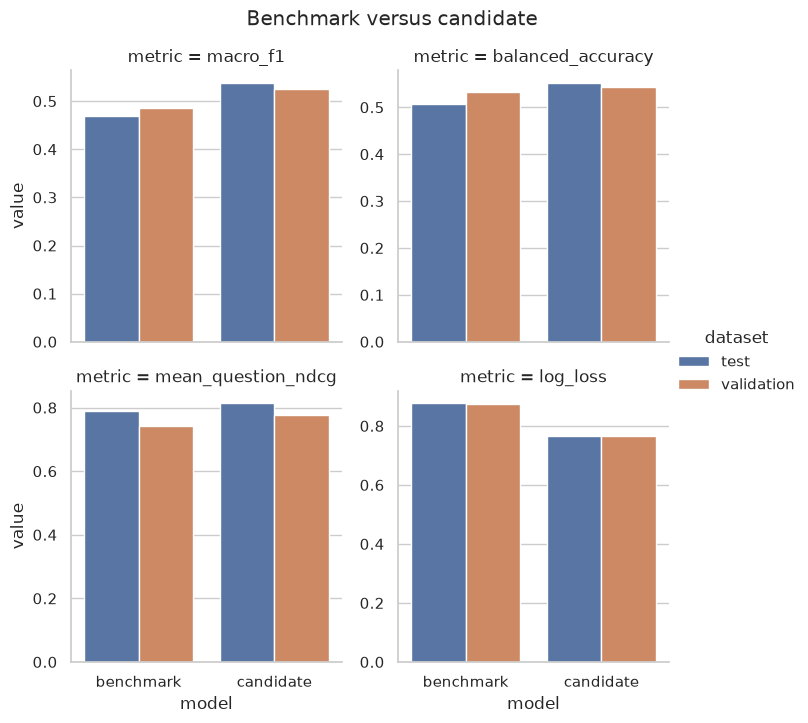

{
  "validation_macro_f1_delta": 0.04096671403745644,
  "validation_mean_question_ndcg_delta": 0.03587159450354083,
  "deployment_gate_passed": true
}


In [13]:
def load_model_bundle(model_artifact_uri, model_name):
    archive_path = download_s3_file(model_artifact_uri, local_dir / "artifacts" / f"{model_name}.tar.gz")
    bundle_path = local_dir / "artifacts" / f"{model_name}.joblib"
    with tarfile.open(archive_path, "r:gz") as archive:
        try:
            member = archive.getmember("model.joblib")
        except KeyError as exc:
            raise FileNotFoundError("model.joblib is missing from the SageMaker artifact") from exc
        extracted = archive.extractfile(member)
        if extracted is None:
            raise FileNotFoundError("Could not read model.joblib from the SageMaker artifact")
        bundle_path.write_bytes(extracted.read())
    bundle = joblib.load(bundle_path)
    expected_keys = {"model", "model_type", "feature_columns", "metrics", "schema_version"}
    missing_keys = sorted(expected_keys - set(bundle))
    if missing_keys:
        raise ValueError(f"{model_name} artifact is missing keys: {missing_keys}")
    return bundle

benchmark_bundle = load_model_bundle(
    benchmark_description["ModelArtifacts"]["S3ModelArtifacts"], "benchmark"
)
candidate_bundle = load_model_bundle(
    candidate_description["ModelArtifacts"]["S3ModelArtifacts"], "candidate"
)

evaluation_rows = []
for model_name, bundle in [("benchmark", benchmark_bundle), ("candidate", candidate_bundle)]:
    validation_metrics = bundle["metrics"]["validation"]
    test_metrics = evaluate_model(bundle["model"], splits["test"], bundle["feature_columns"])
    for dataset_name, metrics in [("validation", validation_metrics), ("test", test_metrics)]:
        evaluation_rows.append({"model": model_name, "dataset": dataset_name, **metrics})

evaluation = pd.DataFrame(evaluation_rows).set_index(["model", "dataset"]).sort_index()
display(evaluation.style.format("{:.4f}"))

comparison_metrics = ["macro_f1", "balanced_accuracy", "mean_question_ndcg", "log_loss"]
plot_frame = evaluation.reset_index().melt(
    id_vars=["model", "dataset"],
    value_vars=comparison_metrics,
    var_name="metric",
    value_name="value",
)
g = sns.catplot(
    data=plot_frame,
    x="model", y="value", hue="dataset", col="metric",
    kind="bar", col_wrap=2, sharey=False, height=3.5,
)
g.fig.suptitle("Benchmark versus candidate", y=1.03)
plt.show()

validation_macro_delta = float(
    evaluation.loc[("candidate", "validation"), "macro_f1"]
    - evaluation.loc[("benchmark", "validation"), "macro_f1"]
)

validation_ndcg_delta = float(
    evaluation.loc[("candidate", "validation"), "mean_question_ndcg"]
    - evaluation.loc[("benchmark", "validation"), "mean_question_ndcg"]
)

deployment_gate_passed = bool(
    validation_macro_delta >= 0
    and validation_ndcg_delta >= -0.02
)

print(json.dumps({
    "validation_macro_f1_delta": validation_macro_delta,
    "validation_mean_question_ndcg_delta": validation_ndcg_delta,
    "deployment_gate_passed": deployment_gate_passed,
}, indent=2))

if REQUIRE_BENCHMARK_IMPROVEMENT and not deployment_gate_passed:
    raise RuntimeError(
        "Candidate did not pass the predeclared validation gate. "
        "Debug/tune it before deployment, or set "
        "REQUIRE_BENCHMARK_IMPROVEMENT=False only with documented justification."
    )


### Error analysis and model interpretation

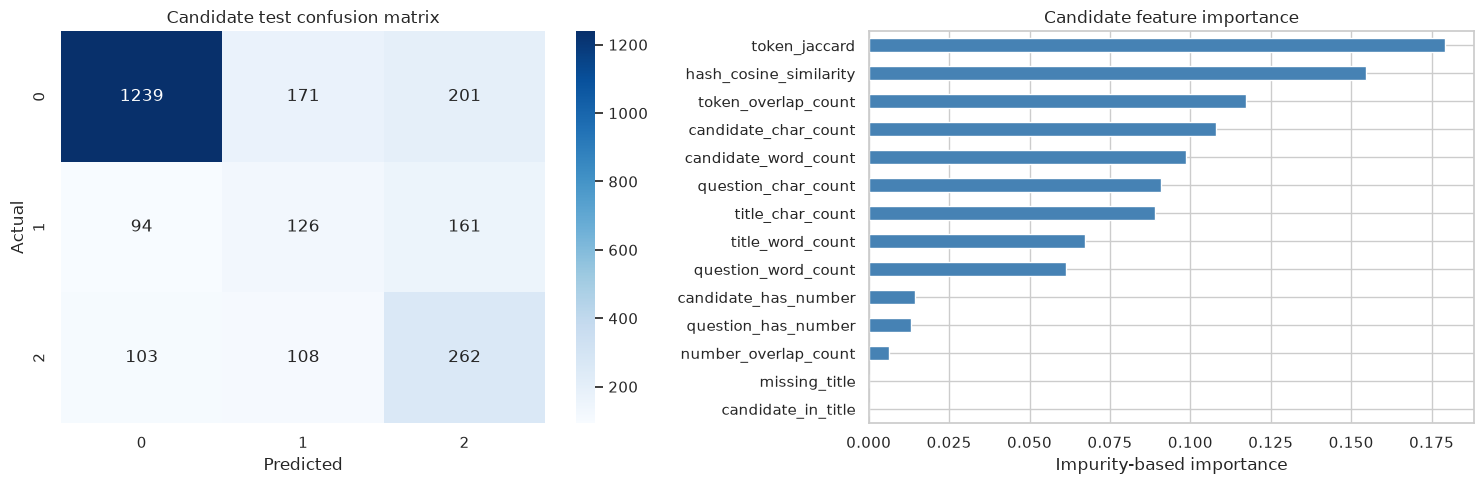

,record_id,qid,asin,source,question_type,label,prediction,expected_relevance
0,d18bbc618b704db9f8490dbb57e67f4a77372d7c,225,B002PUM6MS,attribute,yes_no,1,0,0.191127
2,e5bc1f4cf0570c3fd8af08aaa49f3322e0f6f93d,225,B002PUM6MS,cqa,yes_no,1,0,0.973908
3,0959beb2e3d36f9ab0c6c23509097cf1362cff7e,225,B002PUM6MS,review,yes_no,1,2,1.001069
6,d68cca8bb381705514612cf3377860daebffdb72,225,B002PUM6MS,description,yes_no,0,1,1.064641
10,36a6ff7d85b90ac26297d9ac9da9507f0903ee1c,250,B0031XXW4O,cqa,dimensions,1,2,1.336995
12,475537e5fac07fdc3a3745db2bacea801e5fef17,250,B0031XXW4O,cqa,dimensions,1,2,1.211777
13,50a34ffaf64296a3805c5af51982f6e52f7f9e6b,250,B0031XXW4O,cqa,dimensions,0,1,1.275341
14,adef4d23474e2e2a8c7b197931c1291e68291938,250,B0031XXW4O,review,dimensions,0,2,1.263289
18,11829dcf9bc02ef97047b0758f04a011d93ac8e6,250,B0031XXW4O,review,dimensions,0,2,1.563586
20,7cb28fb4f0f78f70067be6fee3878321b8877707,351,B00ATJSDGK,attribute,yes_no,0,2,1.155199


Candidate test errors: 838 of 2,465


In [14]:
test_frame = splits["test"].copy()
candidate_model = candidate_bundle["model"]
test_predictions = candidate_model.predict(test_frame[CANDIDATE_FEATURES]).astype(int)
test_probabilities = probability_matrix(candidate_model, test_frame[CANDIDATE_FEATURES])
test_expected_relevance = test_probabilities @ CLASS_LABELS.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
matrix = confusion_matrix(test_frame["label"].astype(int), test_predictions, labels=CLASS_LABELS)
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, ax=axes[0],
)
axes[0].set(title="Candidate test confusion matrix", xlabel="Predicted", ylabel="Actual")

importance = pd.Series(
    candidate_model.feature_importances_, index=CANDIDATE_FEATURES
).sort_values(ascending=True)
importance.tail(14).plot.barh(ax=axes[1], color="steelblue")
axes[1].set(title="Candidate feature importance", xlabel="Impurity-based importance")
plt.tight_layout()
plt.show()

error_sample = test_frame.loc[test_predictions != test_frame["label"].to_numpy(), [
    "record_id", "qid", "asin", "source", "question_type", "label",
]].copy()
error_sample["prediction"] = test_predictions[test_predictions != test_frame["label"].to_numpy()]
error_sample["expected_relevance"] = test_expected_relevance[
    test_predictions != test_frame["label"].to_numpy()
]
display(error_sample.head(20))
print(f"Candidate test errors: {len(error_sample):,} of {len(test_frame):,}")

## 8 Deploy the candidate with SageMaker Batch Transform

The production input contains one headerless CSV record per candidate pair. SageMaker splits on line boundaries and sends multiple records per request. The custom inference functions enforce the 14-column schema and emit five columns per record: predicted class, expected relevance, and probabilities for classes 0, 1, and 2.

In [15]:
batch_output_uri = f"s3://{bucket}/{model_prefix}/batch-output/"

if RUN_BATCH_TRANSFORM:
    transformer = candidate_estimator.transformer(
        instance_count=1,
        instance_type=TRANSFORM_INSTANCE_TYPE,
        strategy="MultiRecord",
        assemble_with="Line",
        output_path=batch_output_uri,
        accept="text/csv",
        max_payload=6,
        env={"SAGEMAKER_MODEL_SERVER_TIMEOUT": "120"},
        tags=[
            {"Key": "project", "Value": PROJECT_NAME},
            {"Key": "course", "Value": "AAI-540"},
            {"Key": "model-run-id", "Value": model_run_id},
        ],
    )
    transformer.transform(
        data=production_input_uri,
        data_type="S3Prefix",
        content_type="text/csv",
        split_type="Line",
        wait=True,
        logs=True,
    )
    transform_job_name = transformer.latest_transform_job.name
    transform_description = sm_client.describe_transform_job(TransformJobName=transform_job_name)
    if transform_description["TransformJobStatus"] != "Completed":
        raise RuntimeError(f"Batch Transform did not complete: {transform_description}")
else:
    raise RuntimeError(
        "RUN_BATCH_TRANSFORM=False: training/evaluation completed, but deployment was intentionally skipped."
    )

prediction_key = f"{model_prefix}/batch-output/production.csv.out"
prediction_path = local_dir / "batch-output" / "production.csv.out"
prediction_path.parent.mkdir(parents=True, exist_ok=True)
s3.download_file(bucket, prediction_key, str(prediction_path))
prediction_columns = [
    "prediction", "expected_relevance", "probability_0", "probability_1", "probability_2"
]
production_predictions = pd.read_csv(prediction_path, header=None, names=prediction_columns)
if len(production_predictions) != len(splits["production"]):
    raise ValueError(
        f"Expected {len(splits['production']):,} predictions, got {len(production_predictions):,}"
    )

scored_production = pd.concat([
    splits["production"][["record_id", "qid", "asin"]].reset_index(drop=True),
    production_predictions.reset_index(drop=True),
], axis=1)
assert np.allclose(
    scored_production[["probability_0", "probability_1", "probability_2"]].sum(axis=1),
    1.0,
    atol=1e-5,
)
display(scored_production.head(10))
print(json.dumps({
    "transform_job": transform_job_name,
    "status": transform_description["TransformJobStatus"],
    "input": production_input_uri,
    "output": f"s3://{bucket}/{prediction_key}",
    "rows_scored": len(scored_production),
}, indent=2))

/opt/conda/lib/python3.12/site-packages/sagemaker/model.py:347: SageMakerV2DeprecationWarning: SKLearnModel is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker:Creating model with name: aai540-product-qa-candidate-2026-10-17-01-35-37-762
/opt/conda/lib/python3.12/site-packages/sagemaker/transformer.py:115: SageMakerV2DeprecationWarning: Transformer is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.shapes.TransformJob`.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for t

....................../usr/local/lib/python3.10/dist-packages/sagemaker_containers/_server.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
2026-10-17 01:39:14,701 INFO - sagemaker-containers - No GPUs detected (normal if no gpus installed)
2026-10-17 01:39:14,703 INFO - sagemaker-containers - No GPUs detected (normal if no gpus installed)
2026-10-17 01:39:14,703 INFO - sagemaker-containers - nginx config: 
worker_processes auto;
daemon off;
pid /tmp/nginx.pid;
error_log  /dev/stderr;
worker_rlimit_nofile 4096;
events {
  worker_connections 2048;
}
http {
  include /etc/nginx/mime.types;
  default_type application/octet-stream;
  access_log /dev/stdout combined;
  upstream gunicorn {
    server unix:/tmp/gunicorn.sock;
  }
  server {
    listen 8080 deferred;
    cli

,record_id,qid,asin,prediction,expected_relevance,probability_0,probability_1,probability_2
0,87f8b51f1a75bc678982bf9d0f0f725abb74bb92,46,B00IY7B5CS,0,0.842326,0.457531,0.242611,0.299857
1,3bc8a3f6ef4d629263e99570a46f2b46690c3a5f,46,B00IY7B5CS,1,1.034533,0.244659,0.476148,0.279192
2,fbda77a7823fba8b1211dbd85ba459f5a21abf61,46,B00IY7B5CS,1,1.092377,0.246218,0.415187,0.338595
3,c898f666a02e985610c7d9589d003e2161d825c4,46,B00IY7B5CS,1,0.992894,0.243350,0.520406,0.236244
4,41a1e639dc95731ff9fb05e5d8b7abead81f4815,46,B00IY7B5CS,1,0.985635,0.320573,0.373219,0.306208
5,f14d3dad745652cab27112d303961c642f10c911,46,B00IY7B5CS,0,0.136152,0.904126,0.055597,0.040277
6,489bb20bf287dce00bc8346b9f0d2436ab3e18c2,46,B00IY7B5CS,0,0.722472,0.466653,0.344222,0.189125
7,64560b8e55fd1f92d59bd89eac8cef5dabf0043f,46,B00IY7B5CS,0,0.201248,0.873226,0.052301,0.074474
8,09e1e409849f69a66d47c2e19fa9971701335f2a,46,B00IY7B5CS,0,0.982200,0.407623,0.202554,0.389823
9,25179bdcbc9c231258d15d48325a438c69a3df83,46,B00IY7B5CS,0,0.175029,0.884743,0.055485,0.059772


{
  "transform_job": "aai540-product-qa-candidate-2026-10-17-01-35-38-687",
  "status": "Completed",
  "input": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/modeling/20261017_012600/batch-input/production.csv",
  "output": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/modeling/20261017_012600/batch-output/production.csv.out",
  "rows_scored": 9946
}


## 9 Persist an auditable modeling and deployment receipt

In [16]:
evaluation_records = []
for (model_name, dataset_name), row in evaluation.iterrows():
    evaluation_records.append({
        "model": model_name,
        "dataset": dataset_name,
        **{metric: float(value) for metric, value in row.items()},
    })

receipt = {
    "project": PROJECT_NAME,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_run_id": model_run_id,
    "source_data_run_id": source_run_id,
    "source_run_summary": f"s3://{bucket}/{summary_key}",
    "framework": {"name": "scikit-learn", "sagemaker_version": SKLEARN_FRAMEWORK_VERSION},
    "benchmark": {
        "description": "Depth-two decision tree using two lexical similarity features",
        "features": BENCHMARK_FEATURES,
        "training_job": BENCHMARK_JOB_NAME,
        "model_artifact": benchmark_description["ModelArtifacts"]["S3ModelArtifacts"],
    },
    "candidate": {
        "description": "Class-balanced random forest over inference-time scalar features",
        "features": CANDIDATE_FEATURES,
        "training_job": CANDIDATE_JOB_NAME,
        "model_artifact": candidate_description["ModelArtifacts"]["S3ModelArtifacts"],
    },
    "evaluation": evaluation_records,
    "deployment_gate": {
        "validation_macro_f1_delta": float(validation_macro_delta),
        "validation_mean_question_ndcg_delta": float(validation_ndcg_delta),
        "passed": bool(deployment_gate_passed),
    },
    "deployment": {
        "mode": "SageMaker Batch Transform",
        "transform_job": transform_job_name,
        "status": transform_description["TransformJobStatus"],
        "instance_type": TRANSFORM_INSTANCE_TYPE,
        "input": production_input_uri,
        "output": f"s3://{bucket}/{prediction_key}",
        "rows_scored": int(len(scored_production)),
    },
}
receipt_key = f"{model_prefix}/modeling_receipt.json"
s3.put_object(
    Bucket=bucket,
    Key=receipt_key,
    Body=json.dumps(receipt, indent=2).encode("utf-8"),
    ContentType="application/json",
)
print(json.dumps(receipt, indent=2))
print(f"\nModeling receipt: s3://{bucket}/{receipt_key}")

{
  "project": "product-qa",
  "created_at_utc": "2026-10-17T01:41:33.873259+00:00",
  "model_run_id": "20261017_012600",
  "source_data_run_id": "20261017_011905",
  "source_run_summary": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20261017_011905/run_summary.json",
  "framework": {
    "name": "scikit-learn",
    "sagemaker_version": "1.4-2"
  },
  "benchmark": {
    "description": "Depth-two decision tree using two lexical similarity features",
    "features": [
      "hash_cosine_similarity",
      "token_jaccard"
    ],
    "training_job": "aai540-product-qa-benchmark-2026-10-17-01-26-15-265",
    "model_artifact": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/modeling/20261017_012600/artifacts/benchmark/aai540-product-qa-benchmark-2026-10-17-01-26-15-265/output/model.tar.gz"
  },
  "candidate": {
    "description": "Class-balanced random forest over inference-time scalar features",
    "features": [
      "question_char_count",
      "candidate_char_c

## Completion checklist and cost control

- **Benchmark in SageMaker:** a managed training job produced a versioned two-feature benchmark artifact.
- **First model iteration:** a separate managed training job validated inputs, trained the random forest, logged metrics, and packaged its inference schema.
- **Evaluation:** validation and untouched test results compare both artifacts; the deployment gate uses validation only, preserving the test split for final reporting.
- **Deployment:** a completed Batch Transform job scored every production record and stored ordered predictions in S3.

Batch Transform releases its compute when the job completes, so there is no real-time endpoint to delete. S3 artifacts, SageMaker model metadata, training histories, transform history, and CloudWatch logs remain as reproducibility evidence and incur only their normal storage/log charges. Delete those artifacts through your lab's approved cleanup process when they are no longer needed.